# Feature Patterns and Random Forest Selection

This experiment uses 20 candidate application-time fields with observations in each of the project training years. The prediction target is the recorded contract outcome in Lending Club Data. Random forest was used to rank source fields and a ridge logistic regression was used for the final probability comparison.

## Summary

The temporal selection rule kept **5 source fields**, represented by **22 model columns**. In January–March 2015 after recalibration, log loss was **0.468003** for the selected model and **0.463339** for the model using all available fields under the same engineering recipe. The prior engineered model had log loss **0.463457**.

## Design

The transformation rules were learned on 33,257 loans originated in 2010–2011. A random forest fitted on those loans ranked source fields on 18,523 January–June 2012 loans. Each source field and all its derived columns were shuffled together, within contract term. A separate 34,844-loan July–December 2012 sample selected the fewest ranked fields within one paired standard error of the lowest logistic log loss. The standard-error rule favours a smaller model when the differences are small.

Both logistic models refit their coefficients on 2010–2012. The comparison uses the same term calibration procedure and loan samples as the previous analysis. It covers 2013, 2014, and January–March 2015. For the primary 2015 comparison, each model's term intercepts were updated on 2014. Earlier project results informed the current workflow and provide reference benchmarks.

Run the accompanying Python script to regenerate the tables. The notebook presents the resulting evidence.

## Feature engineering by pattern

Money and counts with a long positive tail can use a capped signed log1p transform. Sparse amounts and counts become any-event indicators. DTI and revolving utilisation use training quartile hinges to allow the slope to change. Employment length uses ordered years and endpoint indicators. Nominal categories use one-hot encoding with a pooled rare group.

In [1]:
from pathlib import Path

import pandas as pd

repo = Path.cwd()
if not (repo / "models").exists():
    repo = repo.parent
folder = repo / "research/random_forest_feature_selection_20261122"
patterns = pd.read_csv(folder / "feature_patterns.csv")
ranks = pd.read_csv(folder / "rf_group_importance.csv")
sizes = pd.read_csv(folder / "feature_count_selection.csv")
metrics = pd.read_csv(folder / "model_comparison.csv")
paired = pd.read_csv(folder / "paired_rf_selection.csv")
pattern_view = patterns[["field", "pattern", "missing_share", "zero_share_observed", "positive_p95_median",
          "treatment", "encoded_columns_used", "selected_by_rf"]]
pattern_view.round(3)

field,pattern,missing_share,zero_share_observed,positive_p95_median,treatment,encoded_columns_used,selected_by_rf
annual_inc,Money,0.000,0.000,2.367,Capped linear,1,True
dti,Percentage,0.000,0.004,1.756,Capped linear,3,False
revol_util,Percentage,0.001,0.024,1.820,Capped linear,4,True
emp_length,Ordered employment band,0.032,0.105,2.000,Ordered years with endpoint indicators,4,False
home_ownership,Nominal category,0.000,NaN,NaN,One-hot with rare categories grouped,3,False
purpose,Nominal category,0.000,NaN,NaN,One-hot with rare categories grouped,13,True
delinq_2yrs,Count,0.000,0.892,3.000,Capped signed log1p,2,False
inq_last_6mths,Count,0.000,0.497,3.000,Capped signed log1p,2,True
mths_since_last_delinq,Months since event,0.658,0.000,2.143,Capped linear,2,True
mths_since_last_record,Months since event,0.946,0.000,1.196,Capped linear,2,False


## Source-field importance

Blue bars represent retained fields. A positive value shows higher log loss after the field is shuffled. The ranking reflects reliance by this forest in early 2012. Correlated fields may substitute for one another.

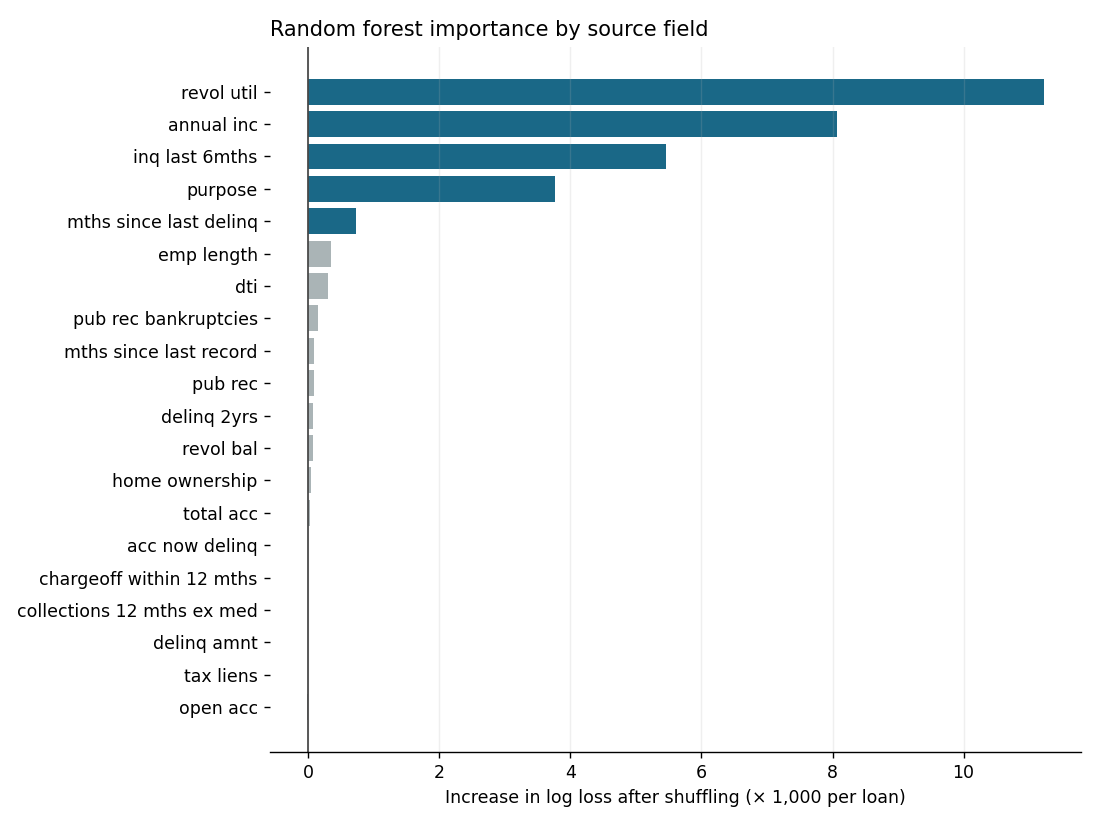

In [2]:
import matplotlib.pyplot as plt

chosen = ranks["selected"]
colors = chosen.map({True: "#1a6887", False: "#aab4b6"})
fig, ax = plt.subplots(figsize=(8.8, 6.6))
labels = ranks.field.str.replace("_", " ", regex=False)
ax.barh(labels, ranks.mean_log_loss_increase * 1000, color=colors)
ax.axvline(0, color="#444444", linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Increase in log loss after shuffling (× 1,000 per loan)")
ax.set_title("Random forest importance by source field", loc="left")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
plt.show()

## Feature count comparison

These results use July–December 2012. The selected count is the smallest eligible count within one paired standard error of the lowest log loss.

In [3]:
sizes[["fields", "encoded_columns", "log_loss", "auc", "within_paired_se"]].round(6)

fields,encoded_columns,log_loss,auc,within_paired_se
3,7,0.424701,0.640278,False
5,22,0.423149,0.648724,True
7,29,0.423564,0.646463,False
10,34,0.423910,0.646667,False
13,40,0.424342,0.647368,False
15,42,0.422856,0.650819,True


## Later-period results

Smaller log loss is better. The calibration gap is mean predicted Bad rate minus observed Bad rate in percentage points.

In [4]:
primary = metrics.scenario.eq("Recorded outcomes") & metrics["sample"].eq("All loans")
columns = ["cohort", "calibration", "model", "loans", "log_loss", "auc", "gap_pp"]
metrics.loc[primary, columns].sort_values(["cohort", "calibration", "log_loss"]).round(6)

cohort,calibration,model,loans,log_loss,auc,gap_pp
2013,Training offsets,Engineered main effects,134814,0.412673,0.657629,0.457304
2013,Training offsets,Pattern + all-field ridge,134814,0.412784,0.657019,0.428321
2013,Training offsets,Five-variable WoE,134814,0.413666,0.653211,0.029341
2013,Training offsets,Pattern + RF-selected ridge,134814,0.414846,0.649224,-0.241776
2014,Training offsets,Pattern + all-field ridge,235619,0.445985,0.654963,-1.067950
2014,Training offsets,Engineered main effects,235619,0.446007,0.654660,-0.940441
2014,Training offsets,Five-variable WoE,235619,0.449292,0.646580,-1.832769
2014,Training offsets,Pattern + RF-selected ridge,235619,0.450951,0.643217,-2.178997
2015 Q1,2014 offsets,Pattern + all-field ridge,84175,0.463339,0.655618,-1.411921
2015 Q1,2014 offsets,Engineered main effects,84175,0.463457,0.654905,-1.385740


## Selection effect and unresolved outcomes

Negative differences favour the selected model over all available fields under the same recipe. Approximate paired intervals assume independent loans and fixed predictions. The extreme cases place all 102 unresolved 60-month loans into Good or Bad.

In [5]:
last = paired.loc[paired.cohort.eq("2015 Q1") & paired.calibration.eq("2014 offsets")]
last[["scenario", "sample", "loans", "selected_minus_full_log_loss", "lower_95", "upper_95"]].round(6)

scenario,sample,loans,selected_minus_full_log_loss,lower_95,upper_95
Recorded outcomes,All loans,84175,0.004664,0.004116,0.005212
Recorded outcomes,36 months,56569,0.004218,0.003591,0.004845
Recorded outcomes,60 months,27606,0.005578,0.004513,0.006643
Unresolved set to Good,All loans,84277,0.004649,0.004102,0.005196
Unresolved set to Good,36 months,56569,0.004218,0.003591,0.004845
Unresolved set to Good,60 months,27708,0.005527,0.004465,0.006589
Unresolved set to Bad,All loans,84277,0.004669,0.004121,0.005217
Unresolved set to Bad,36 months,56569,0.004218,0.003591,0.004845
Unresolved set to Bad,60 months,27708,0.005589,0.004523,0.006656


## Interpretation

In the early fitting cohort, 49.7% of loans had zero recent enquiries. The enquiry field used a zero indicator and a capped log1p count. The positive 95th percentile of annual income was 2.37 times its median, below the experiment's threshold of 3 for applying a log transform. Annual income therefore used a capped linear term. Revolving utilisation used slope changes at 26.5% and 73.0%, its training quartiles. Missing months since last delinquency accounted for 65.8% of early loans, so the model used a missing indicator alongside the imputed duration.

Five source fields had no varying model columns in the early sample. The 15 other fields contributed 42 columns. The selected combination retained revolving utilisation, annual income, recent credit enquiries, purpose and months since last delinquency. DTI ranked seventh. In July–December 2012, the 15-field model had the lowest log loss (0.422856). The five-field version (0.423149) qualified under the one-standard-error rule.

Across 2013, 2014 and the first quarter of 2015, the five-field version had higher log loss than both previous benchmarks. In 2015 Q1 after 2014 recalibration, omitting the lower-ranked fields raised log loss by 0.004664 per loan relative to the full engineered version (approximate paired 95% interval 0.004116 to 0.005212). This finding held for both contract terms and in the two unresolved-outcome stress cases.

Keeping the 15 available fields with pattern-based engineering and ridge returned results close to the previous engineered main-effects candidate. Its 2015 Q1 log loss was 0.463339, compared with 0.463457 previously. Within this pattern-based pipeline, the broader set yielded better later-period predictions than the RF-selected subset. Differences between the two broad models reflect their combined preprocessing and modelling choices.

## Scorecard model choice

The five-variable WoE scorecard is the preferred primary model at this stage. On the 84,175 labelled loans in January–March 2015, the pattern-based model with 15 fields lowered log loss from 0.466607 to 0.463339, a relative improvement of 0.70%. AUC moved from 0.6449 to 0.6556. That gain came with 42 encoded columns in place of five WoE inputs. The RF-selected model used five source fields represented by 22 columns and produced a higher log loss (0.468003) than the WoE scorecard.

With WoE binning, an analyst can trace each component from the recorded application value through its bin, WoE value and score contribution. The engineered pipeline requires additional checks of caps, imputation values, flags, spline terms, category mappings and scaling. Those steps can be documented and reproduced, and each adds to the work of explaining individual scores and auditing changes.

Retain the broader models for comparison. The current evidence shows a modest difference in prediction metrics and leaves the practical effect at lending decision thresholds unmeasured. The simpler WoE structure makes the model easier to explain and audit under the current project priorities.

[Permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html) · [Permutation importance with correlated fields](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html)